# 04b — Toronto terrain enrichment

## Purpose

Notebook 04 revealed that the pilot DEM is completely flat:

`dem_min_m = 0` and `dem_max_m = 0`.

That was acceptable for the original Sevilla proof-of-concept, but Toronto v2
should retain real terrain variation before SOLWEIG is run.

This notebook therefore:

1. loads the existing U of T SOLWEIG rasters from Notebook 04;
2. downloads open global terrain tiles for the pilot area;
3. decodes the terrain elevations;
4. mosaics the required terrain tiles;
5. reprojects the terrain exactly onto the existing 5 m Toronto raster grid;
6. reconstructs building height from the existing DSM and flat DEM;
7. rebuilds the DSM as:

   `new DSM = real DEM + building height`

8. leaves the canopy surface unchanged;
9. validates alignment and terrain statistics;
10. replaces the SOLWEIG-ready DSM/DEM while retaining backup copies of the
    original flat-terrain rasters.

The terrain source is the **AWS Open Data Terrain Tiles** archive using
Terrarium encoding.

**Kernel:** Python 3.12 - VoxCity

## 1. Imports and project paths

In [1]:
from pathlib import Path
import math
import shutil
import time

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import requests

from PIL import Image
from rasterio.transform import from_bounds
from rasterio.warp import (
    reproject,
    transform_bounds,
    Resampling,
)

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    PROJECT_ROOT = Path(
        "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
    )

TORONTO_DATA = PROJECT_ROOT / "data" / "toronto"
TORONTO_RAW = TORONTO_DATA / "raw"
TORONTO_INTERIM = TORONTO_DATA / "interim"

SOLWEIG_DIR = (
    TORONTO_INTERIM
    / "solweig"
    / "UOFT_PILOT"
)

TERRAIN_CACHE = (
    TORONTO_RAW
    / "terrain_tiles"
    / "UOFT_PILOT"
)

TERRAIN_CACHE.mkdir(
    parents=True,
    exist_ok=True,
)

print("Project root:", PROJECT_ROOT)
print("SOLWEIG directory:", SOLWEIG_DIR)
print("Terrain cache:", TERRAIN_CACHE)

Project root: /scratch/project_2010417/paper3/heat-conditioned-accessibility
SOLWEIG directory: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/solweig/UOFT_PILOT
Terrain cache: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/raw/terrain_tiles/UOFT_PILOT


## 2. Load the existing SOLWEIG rasters

Notebook 04 created:

- `dsm.tif`
- `cdsm.tif`
- `dem.tif`

We use the DSM and DEM to recover the existing building-height surface before
inserting real terrain.

In [2]:
dsm_path = SOLWEIG_DIR / "dsm.tif"
cdsm_path = SOLWEIG_DIR / "cdsm.tif"
dem_path = SOLWEIG_DIR / "dem.tif"

for path in [
    dsm_path,
    cdsm_path,
    dem_path,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Required raster not found: {path}"
        )

with rasterio.open(dsm_path) as src:
    dsm_old = src.read(1).astype(np.float32)
    target_profile = src.profile.copy()
    target_transform = src.transform
    target_crs = src.crs
    target_bounds = src.bounds
    target_shape = src.shape

with rasterio.open(cdsm_path) as src:
    cdsm = src.read(1).astype(np.float32)

with rasterio.open(dem_path) as src:
    dem_old = src.read(1).astype(np.float32)

print("Target CRS:", target_crs)
print("Target shape:", target_shape)
print("Target resolution:", target_profile["transform"].a, "m")
print("Existing DEM range:", float(dem_old.min()), "to", float(dem_old.max()), "m")

Target CRS: EPSG:32617
Target shape: (416, 416)
Target resolution: 5.0 m
Existing DEM range: 0.0 to 0.0 m


## 3. Recover the existing building-height raster

The previous DSM was constructed as:

`DSM = DEM + building height`

Therefore:

`building height = DSM - DEM`

Because the previous DEM is zero everywhere, this is numerically equivalent
to the existing DSM, but keeping the subtraction makes the workflow explicit
and reusable.

In [3]:
building_height = (
    dsm_old - dem_old
).astype(np.float32)

# Protect against small numerical artifacts.
building_height[
    building_height < 0
] = 0

print(
    "Building-height range:",
    float(np.nanmin(building_height)),
    "to",
    float(np.nanmax(building_height)),
    "m",
)

print(
    "Building cells:",
    int(
        np.count_nonzero(
            building_height > 0
        )
    ),
)

Building-height range: 0.0 to 116.81999969482422 m
Building cells: 7671


## 4. Convert the pilot raster bounds to WGS84

The existing SOLWEIG grid is already the exact target grid we want to preserve.

We transform its bounds from EPSG:32617 to geographic coordinates only to
determine which global terrain tiles are required.

In [4]:
west, south, east, north = transform_bounds(
    target_crs,
    "EPSG:4326",
    target_bounds.left,
    target_bounds.bottom,
    target_bounds.right,
    target_bounds.top,
    densify_pts=21,
)

print("WGS84 terrain request bounds:")
print("west :", west)
print("south:", south)
print("east :", east)
print("north:", north)

WGS84 terrain request bounds:
west : -79.40912882640237
south: 43.65415585212342
east : -79.38284210914993
north: 43.673238853826774


## 5. Configure the open terrain-tile source

The AWS Terrain Tiles dataset uses standard Web Mercator slippy-map tiles.

Terrarium pixels encode elevation in metres as:

`elevation = R × 256 + G + B / 256 − 32768`

Zoom level 15 is used here because it provides a terrain surface that is finer
than the final 5 m modelling grid in the Toronto latitude range.

The final product is still resampled to the exact 5 m SOLWEIG grid.

In [5]:
TERRAIN_ZOOM = 15

TERRAIN_URL = (
    "https://s3.amazonaws.com/"
    "elevation-tiles-prod/terrarium/"
    "{z}/{x}/{y}.png"
)

TILE_SIZE = 256

print("Terrain zoom:", TERRAIN_ZOOM)
print("Tile size:", TILE_SIZE)

Terrain zoom: 15
Tile size: 256


## 6. Slippy-map helper functions

In [6]:
def lonlat_to_tile(lon, lat, zoom):
    n = 2 ** zoom

    x = int(
        math.floor(
            (lon + 180.0)
            / 360.0
            * n
        )
    )

    lat_rad = math.radians(lat)

    y = int(
        math.floor(
            (
                1.0
                - math.asinh(
                    math.tan(lat_rad)
                )
                / math.pi
            )
            / 2.0
            * n
        )
    )

    return x, y


def tile_bounds_mercator(x, y, zoom):
    # Web Mercator total world extent.
    origin = 20037508.342789244
    world = 2 * origin
    n = 2 ** zoom
    tile_span = world / n

    left = -origin + x * tile_span
    right = left + tile_span

    top = origin - y * tile_span
    bottom = top - tile_span

    return left, bottom, right, top

## 7. Determine the required terrain tiles

A one-tile buffer is added around the requested range so reprojection near the
pilot boundary does not depend on partially sampled edge pixels.

In [7]:
x_min, y_max = lonlat_to_tile(
    west,
    south,
    TERRAIN_ZOOM,
)

x_max, y_min = lonlat_to_tile(
    east,
    north,
    TERRAIN_ZOOM,
)

BUFFER_TILES = 1

x_values = range(
    x_min - BUFFER_TILES,
    x_max + BUFFER_TILES + 1,
)

y_values = range(
    y_min - BUFFER_TILES,
    y_max + BUFFER_TILES + 1,
)

tile_list = [
    (x, y)
    for y in y_values
    for x in x_values
]

print(
    "Terrain tiles required:",
    len(tile_list),
)

print(
    "X range:",
    min(x for x, y in tile_list),
    "to",
    max(x for x, y in tile_list),
)

print(
    "Y range:",
    min(y for x, y in tile_list),
    "to",
    max(y for x, y in tile_list),
)

Terrain tiles required: 25
X range: 9155 to 9159
Y range: 11955 to 11959


## 8. Download the required Terrarium tiles

Tiles are cached locally. If the notebook is rerun, existing files are reused.

In [8]:
session = requests.Session()

session.headers.update(
    {
        "User-Agent": (
            "heat-conditioned-accessibility "
            "Toronto terrain workflow"
        )
    }
)

tile_paths = {}

for index, (x, y) in enumerate(
    tile_list,
    start=1,
):
    tile_path = (
        TERRAIN_CACHE
        / f"z{TERRAIN_ZOOM}_x{x}_y{y}.png"
    )

    if not tile_path.exists():

        url = TERRAIN_URL.format(
            z=TERRAIN_ZOOM,
            x=x,
            y=y,
        )

        success = False

        for attempt in range(1, 4):

            try:
                response = session.get(
                    url,
                    timeout=60,
                )

                response.raise_for_status()

                tile_path.write_bytes(
                    response.content
                )

                success = True
                break

            except Exception as exc:

                print(
                    f"Attempt {attempt} failed "
                    f"for tile {x}/{y}: {exc}"
                )

                if attempt < 3:
                    time.sleep(
                        5 * attempt
                    )

        if not success:
            raise RuntimeError(
                f"Could not download terrain tile {x}/{y}"
            )

    tile_paths[
        (x, y)
    ] = tile_path

    print(
        f"{index:>3}/{len(tile_list)}",
        tile_path.name,
    )

print("✓ Terrain tiles available locally.")

  1/25 z15_x9155_y11955.png
  2/25 z15_x9156_y11955.png
  3/25 z15_x9157_y11955.png
  4/25 z15_x9158_y11955.png
  5/25 z15_x9159_y11955.png
  6/25 z15_x9155_y11956.png
  7/25 z15_x9156_y11956.png
  8/25 z15_x9157_y11956.png
  9/25 z15_x9158_y11956.png
 10/25 z15_x9159_y11956.png
 11/25 z15_x9155_y11957.png
 12/25 z15_x9156_y11957.png
 13/25 z15_x9157_y11957.png
 14/25 z15_x9158_y11957.png
 15/25 z15_x9159_y11957.png
 16/25 z15_x9155_y11958.png
 17/25 z15_x9156_y11958.png
 18/25 z15_x9157_y11958.png
 19/25 z15_x9158_y11958.png
 20/25 z15_x9159_y11958.png
 21/25 z15_x9155_y11959.png
 22/25 z15_x9156_y11959.png
 23/25 z15_x9157_y11959.png
 24/25 z15_x9158_y11959.png
 25/25 z15_x9159_y11959.png
✓ Terrain tiles available locally.


## 9. Decode Terrarium elevation tiles

Each RGB tile is converted to metres using the Terrarium formula.

In [9]:
def decode_terrarium(path):

    image = Image.open(
        path
    ).convert("RGB")

    rgb = np.asarray(
        image,
        dtype=np.float32,
    )

    elevation = (
        rgb[:, :, 0] * 256.0
        + rgb[:, :, 1]
        + rgb[:, :, 2] / 256.0
        - 32768.0
    )

    return elevation.astype(
        np.float32
    )


sample_xy = tile_list[0]

sample_dem = decode_terrarium(
    tile_paths[sample_xy]
)

print(
    "Sample tile elevation range:",
    float(np.nanmin(sample_dem)),
    "to",
    float(np.nanmax(sample_dem)),
    "m",
)

Sample tile elevation range: 126.6953125 to 158.45703125 m


## 10. Mosaic the downloaded terrain tiles

The tile mosaic remains in Web Mercator (EPSG:3857).

In [10]:
unique_x = sorted(
    set(
        x
        for x, y in tile_list
    )
)

unique_y = sorted(
    set(
        y
        for x, y in tile_list
    )
)

mosaic = np.zeros(
    (
        len(unique_y) * TILE_SIZE,
        len(unique_x) * TILE_SIZE,
    ),
    dtype=np.float32,
)

x_index = {
    x: i
    for i, x in enumerate(
        unique_x
    )
}

y_index = {
    y: i
    for i, y in enumerate(
        unique_y
    )
}

for x, y in tile_list:

    tile_dem = decode_terrarium(
        tile_paths[(x, y)]
    )

    row0 = (
        y_index[y]
        * TILE_SIZE
    )

    col0 = (
        x_index[x]
        * TILE_SIZE
    )

    mosaic[
        row0:row0 + TILE_SIZE,
        col0:col0 + TILE_SIZE,
    ] = tile_dem

print("Mosaic shape:", mosaic.shape)
print(
    "Mosaic elevation range:",
    float(np.nanmin(mosaic)),
    "to",
    float(np.nanmax(mosaic)),
    "m",
)

Mosaic shape: (1280, 1280)
Mosaic elevation range: 74.6796875 to 158.45703125 m


## 11. Define the Web Mercator mosaic transform

In [11]:
left, _, _, top = tile_bounds_mercator(
    unique_x[0],
    unique_y[0],
    TERRAIN_ZOOM,
)

_, bottom, right, _ = tile_bounds_mercator(
    unique_x[-1],
    unique_y[-1],
    TERRAIN_ZOOM,
)

mosaic_transform = from_bounds(
    left,
    bottom,
    right,
    top,
    mosaic.shape[1],
    mosaic.shape[0],
)

print("Terrain mosaic CRS: EPSG:3857")
print("Terrain mosaic bounds:")
print(
    left,
    bottom,
    right,
    top,
)

Terrain mosaic CRS: EPSG:3857
Terrain mosaic bounds:
-8841012.439576626 5410518.610137916 -8834897.477313811 5416633.57240073


## 12. Reproject terrain onto the exact existing 5 m SOLWEIG grid

This is the key alignment step.

We do **not** create a new grid. The terrain is projected directly into the
existing DSM/CDSM/DEM dimensions and transform from Notebook 04.

In [12]:
dem_real = np.full(
    target_shape,
    np.nan,
    dtype=np.float32,
)

reproject(
    source=mosaic,
    destination=dem_real,
    src_transform=mosaic_transform,
    src_crs="EPSG:3857",
    dst_transform=target_transform,
    dst_crs=target_crs,
    src_nodata=None,
    dst_nodata=np.nan,
    resampling=Resampling.bilinear,
)

print(
    "Real DEM range:",
    float(np.nanmin(dem_real)),
    "to",
    float(np.nanmax(dem_real)),
    "m",
)

print(
    "Real DEM mean:",
    float(np.nanmean(dem_real)),
    "m",
)

print(
    "Missing DEM cells:",
    int(
        np.isnan(
            dem_real
        ).sum()
    ),
)

Real DEM range: 88.73968505859375 to 119.85032653808594 m
Real DEM mean: 107.20767974853516 m
Missing DEM cells: 0


## 13. Validate the terrain surface

The U of T pilot should no longer be flat. We inspect its relief and reject a
terrain surface that remains constant or contains missing cells.

In [13]:
if np.isnan(dem_real).any():
    raise RuntimeError(
        "Terrain reprojection produced missing cells."
    )

terrain_relief = (
    float(np.nanmax(dem_real))
    - float(np.nanmin(dem_real))
)

print(
    "Terrain relief across pilot:",
    round(
        terrain_relief,
        2,
    ),
    "m",
)

if terrain_relief < 0.5:
    raise RuntimeError(
        "Terrain surface is unexpectedly flat."
    )

print(
    "✓ Real terrain variation detected."
)

Terrain relief across pilot: 31.11 m
✓ Real terrain variation detected.


## 14. Rebuild the DSM using real terrain

Building heights remain relative heights above ground.

Therefore:

`DSM_real = DEM_real + building_height`

In [14]:
dsm_real = (
    dem_real
    + building_height
).astype(
    np.float32
)

print(
    "New DSM range:",
    float(np.nanmin(dsm_real)),
    "to",
    float(np.nanmax(dsm_real)),
    "m",
)

print(
    "Canopy surface remains unchanged:",
    float(np.nanmin(cdsm)),
    "to",
    float(np.nanmax(cdsm)),
    "m",
)

New DSM range: 88.73968505859375 to 216.92864990234375 m
Canopy surface remains unchanged: 0.0 to 13.978205680847168 m


## 15. Compare old and new surfaces

In [15]:
comparison = pd.DataFrame(
    {
        "surface": [
            "Old DEM",
            "Real DEM",
            "Old DSM",
            "Real-terrain DSM",
            "CDSM",
        ],
        "min": [
            float(np.nanmin(dem_old)),
            float(np.nanmin(dem_real)),
            float(np.nanmin(dsm_old)),
            float(np.nanmin(dsm_real)),
            float(np.nanmin(cdsm)),
        ],
        "mean": [
            float(np.nanmean(dem_old)),
            float(np.nanmean(dem_real)),
            float(np.nanmean(dsm_old)),
            float(np.nanmean(dsm_real)),
            float(np.nanmean(cdsm)),
        ],
        "max": [
            float(np.nanmax(dem_old)),
            float(np.nanmax(dem_real)),
            float(np.nanmax(dsm_old)),
            float(np.nanmax(dsm_real)),
            float(np.nanmax(cdsm)),
        ],
    }
)

display(comparison)

,surface,min,mean,max
0,Old DEM,0.000000,0.000000,0.000000
1,Real DEM,88.739685,107.207680,119.850327
2,Old DSM,0.000000,0.470333,116.820000
3,Real-terrain DSM,88.739685,107.678024,216.928650
4,CDSM,0.000000,0.126081,13.978206


## 16. Visualize terrain enrichment

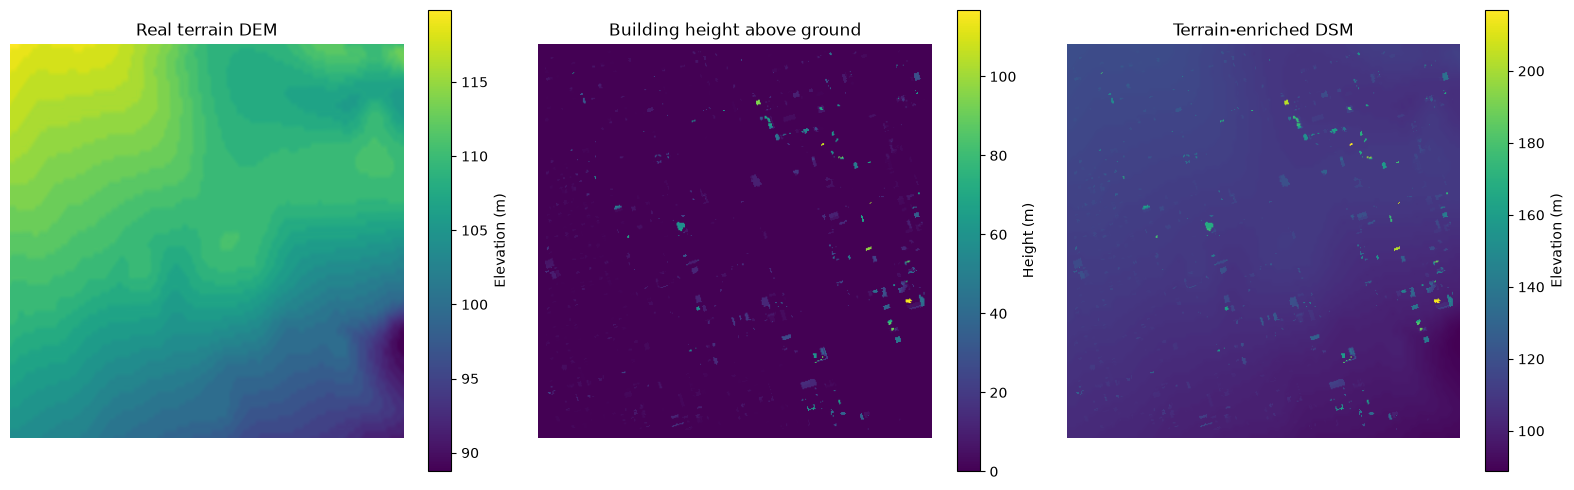

In [16]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5),
)

im0 = axes[0].imshow(
    dem_real,
    origin="upper",
)

axes[0].set_title(
    "Real terrain DEM"
)

plt.colorbar(
    im0,
    ax=axes[0],
    label="Elevation (m)",
)


im1 = axes[1].imshow(
    building_height,
    origin="upper",
)

axes[1].set_title(
    "Building height above ground"
)

plt.colorbar(
    im1,
    ax=axes[1],
    label="Height (m)",
)


im2 = axes[2].imshow(
    dsm_real,
    origin="upper",
)

axes[2].set_title(
    "Terrain-enriched DSM"
)

plt.colorbar(
    im2,
    ax=axes[2],
    label="Elevation (m)",
)

for ax in axes:
    ax.set_axis_off()

plt.tight_layout()
plt.show()

## 17. Preserve the original flat-terrain rasters

Before replacement, copies are stored with `_flat` suffixes.

This makes the methodological change fully reversible and auditable.

In [17]:
dsm_flat_backup = (
    SOLWEIG_DIR
    / "dsm_flat.tif"
)

dem_flat_backup = (
    SOLWEIG_DIR
    / "dem_flat.tif"
)

if not dsm_flat_backup.exists():
    shutil.copy2(
        dsm_path,
        dsm_flat_backup,
    )

if not dem_flat_backup.exists():
    shutil.copy2(
        dem_path,
        dem_flat_backup,
    )

print(
    "Flat-terrain backups:"
)

print(
    "-",
    dsm_flat_backup,
)

print(
    "-",
    dem_flat_backup,
)

Flat-terrain backups:
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/solweig/UOFT_PILOT/dsm_flat.tif
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/solweig/UOFT_PILOT/dem_flat.tif


## 18. Write the real DEM and rebuilt DSM

The original filenames are retained so the next SOLWEIG notebook can use the
same expected file paths.

In [18]:
output_profile = (
    target_profile.copy()
)

output_profile.update(
    dtype="float32",
    count=1,
    nodata=None,
    compress="lzw",
)


with rasterio.open(
    dem_path,
    "w",
    **output_profile,
) as dst:

    dst.write(
        dem_real.astype(
            np.float32
        ),
        1,
    )


with rasterio.open(
    dsm_path,
    "w",
    **output_profile,
) as dst:

    dst.write(
        dsm_real.astype(
            np.float32
        ),
        1,
    )


print("Updated:")
print("-", dem_path)
print("-", dsm_path)

print()
print(
    "CDSM unchanged:"
)
print("-", cdsm_path)

Updated:
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/solweig/UOFT_PILOT/dem.tif
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/solweig/UOFT_PILOT/dsm.tif

CDSM unchanged:
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/solweig/UOFT_PILOT/cdsm.tif


## 19. Validate final SOLWEIG input alignment

In [19]:
validation_rows = []

raster_metadata = []

for path in [
    dsm_path,
    cdsm_path,
    dem_path,
]:

    with rasterio.open(
        path
    ) as src:

        array = src.read(1)

        validation_rows.append(
            {
                "file": path.name,
                "crs": str(src.crs),
                "width": src.width,
                "height": src.height,
                "res_x": src.res[0],
                "res_y": src.res[1],
                "min": float(
                    np.nanmin(
                        array
                    )
                ),
                "mean": float(
                    np.nanmean(
                        array
                    )
                ),
                "max": float(
                    np.nanmax(
                        array
                    )
                ),
            }
        )

        raster_metadata.append(
            (
                src.shape,
                src.crs,
                src.transform,
                src.bounds,
            )
        )

display(
    pd.DataFrame(
        validation_rows
    )
)

if not all(
    metadata
    == raster_metadata[0]
    for metadata
    in raster_metadata[1:]
):
    raise RuntimeError(
        "Final SOLWEIG rasters are not perfectly aligned."
    )

print(
    "✓ DSM, CDSM, and DEM remain perfectly aligned."
)

,file,crs,width,height,res_x,res_y,min,mean,max
0,dsm.tif,EPSG:32617,416,416,5.0,5.0,88.739685,107.678024,216.928650
1,cdsm.tif,EPSG:32617,416,416,5.0,5.0,0.000000,0.126081,13.978206
2,dem.tif,EPSG:32617,416,416,5.0,5.0,88.739685,107.207680,119.850327


✓ DSM, CDSM, and DEM remain perfectly aligned.


## 20. Final terrain-enrichment summary

In [20]:
summary = {
    "model": "UOFT_PILOT",
    "terrain_source": (
        "AWS Open Data Terrain Tiles / Terrarium"
    ),
    "terrain_zoom": TERRAIN_ZOOM,
    "target_crs": str(target_crs),
    "target_resolution_m": (
        target_profile[
            "transform"
        ].a
    ),
    "terrain_min_m": float(
        np.nanmin(
            dem_real
        )
    ),
    "terrain_mean_m": float(
        np.nanmean(
            dem_real
        )
    ),
    "terrain_max_m": float(
        np.nanmax(
            dem_real
        )
    ),
    "terrain_relief_m": float(
        terrain_relief
    ),
    "building_height_max_m": float(
        np.nanmax(
            building_height
        )
    ),
    "final_dsm_max_m": float(
        np.nanmax(
            dsm_real
        )
    ),
    "canopy_max_m": float(
        np.nanmax(
            cdsm
        )
    ),
}

for key, value in summary.items():
    print(
        f"{key}: {value}"
    )

model: UOFT_PILOT
terrain_source: AWS Open Data Terrain Tiles / Terrarium
terrain_zoom: 15
target_crs: EPSG:32617
target_resolution_m: 5.0
terrain_min_m: 88.73968505859375
terrain_mean_m: 107.20767974853516
terrain_max_m: 119.85032653808594
terrain_relief_m: 31.110641479492188
building_height_max_m: 116.81999969482422
final_dsm_max_m: 216.92864990234375
canopy_max_m: 13.978205680847168


## Interpretation and next step

The U of T pilot now contains a non-flat terrain surface while preserving the
Toronto-enriched building-height and canopy information.

The SOLWEIG input chain is therefore:

**Toronto 3D building heights + real terrain + VoxCity canopy
→ aligned DSM / CDSM / DEM at 5 m**

This is a methodological improvement over the flat-terrain Sevilla PoC.

The next notebook can now move to the thermal scenario itself:

**`05_toronto_weather_and_solweig.ipynb`**

The Toronto thermal experiment should prioritize a **single common hot-afternoon
timestep** (for example 15:00 local time) or an observed hot-day sequence,
rather than using cell-wise daily-maximum UTCI as the principal explanatory
surface.